# Кейс 6
## Прогнозирование энергопотребления металлургического завода
### Описание кейса: требуется спрогнозировать активную мощность энергопотребления завода по 15-минутным интервалам на основе показателей реактивной мощности, коэффициента нагрузки, выбросов CO2 и календарного графикаа 

Проанализируем описание датасета, приведенного в источнике:

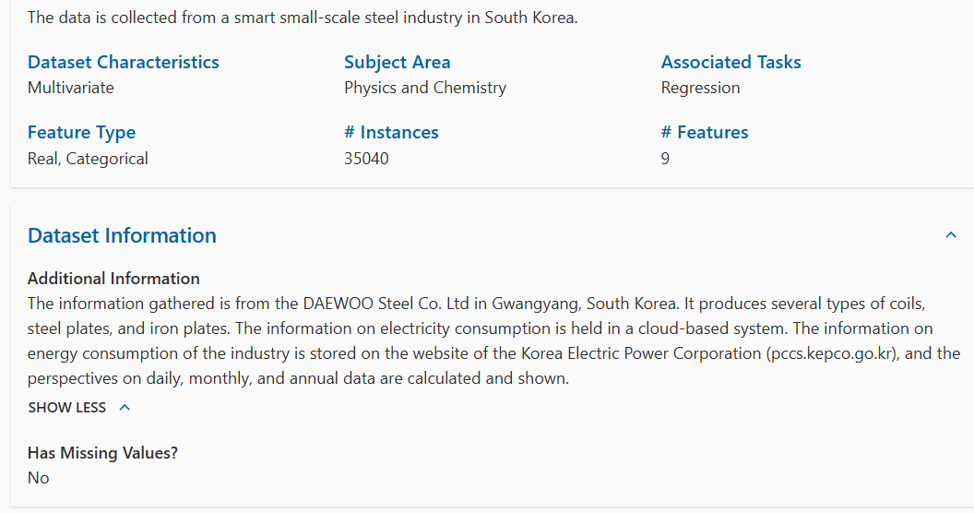

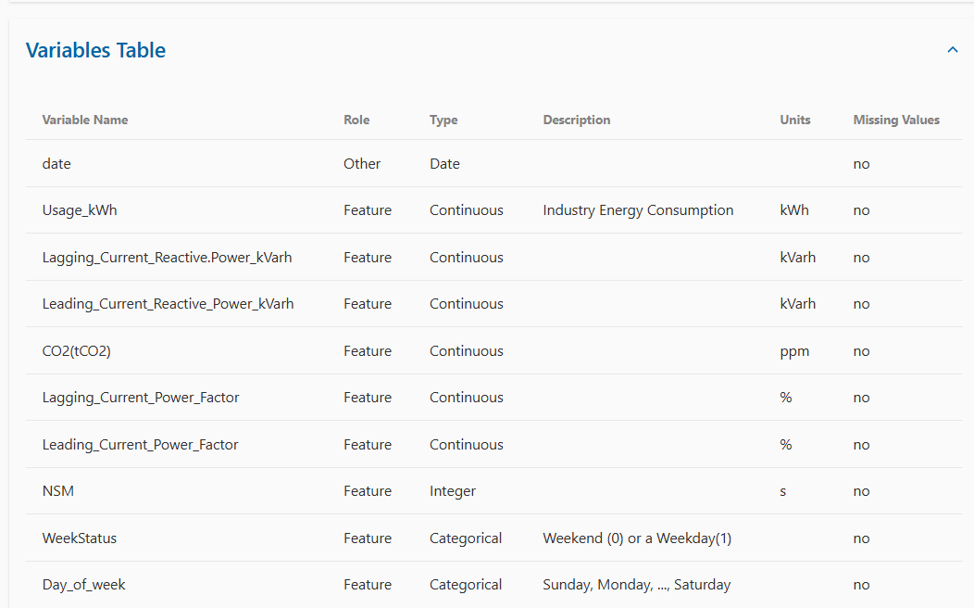

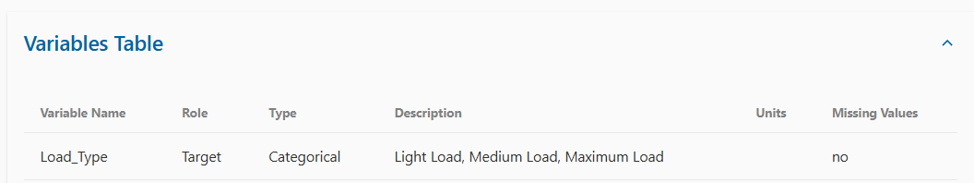

Согласно приведенному описанию, пропусков в данных нет. Это надо проверить!!! В датасете есть непрерывные величины, категориальные, а также даты. В нашем задании целевой переменной (таргетом) является показатель Usage_kWh.

### Что известно про целевую переменную из описания:

Usage_kWh — непрерывная, ≥ 0

Тип задачи: регрессия временного ряда (15-мин интервалы).

### Что важно для модели (надо определить):

- есть ли выраженная суточная/недельная сезонность;

- насколько Usage_kWh объясняется реактивной мощностью и power factor (показывает насколько полно энергия идет на работу, идеальный случай PF = 1, тогда вся энергия идет на совершение работы): Usage_kWh - полезная энергия, реактивная мощность (Lagging, Leading) направлена на создание магнитных полей;

- как ведёт себя CO2 (скорее всего, производная от Usage_kWh);

- как Load_Type соотносится с уровнем мощности.

Давайте внимательно проанализируем сам датасет

In [1]:
# Импорт библиотек и окружения
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import LabelEncoder

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Воспроизводимость
np.random.seed(42)

# Папка для сохранения графиков для последующего формирования отчета (для удобства)
import os
os.makedirs("eda_plots", exist_ok=True)

def save(fig, name):
    """Сохранить график в папку eda_plots."""
    fig.savefig(f"eda_plots/{name}.png", dpi=100, bbox_inches="tight")

In [2]:
# Загрузка (учитываем BOM в начале файла — используем utf-8-sig и игнорируемы спецсимволы)
df = pd.read_csv("steel+industry+energy+consumption/Steel_industry_data.csv", encoding="utf-8-sig")

Посмотрим первые 5 строк датасета

In [3]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


Выполним анализ датасета на пропуски, дубликаты

In [5]:
print("Размер:", df.shape)
print("\nТипы:\n", df.dtypes)
print("\nПропуски:\n", df.isna().sum())
print("\nДубликаты строк:", df.duplicated().sum())



# Проверим, что даты по возрастанию и без дублей
print("\nДата min/max:", df['date'].min(), df['date'].max()) # покажем самую первую и самую последнюю дату
print("Дубликаты timestamp:", df['date'].duplicated().sum()) # Нет ли дублирующихся записей

# Проверим непрерывность: разница между соседними строками (нет ли у нас пустот и дыр во времени, должны быть отрицательные разницы при перехода на новые сутки 23:45 - 0:00)
diffs = df['date'].diff().dropna().value_counts()
print("\nЧастоты интервалов между строками:\n", diffs.head())

# Базовые категории
for col in ['WeekStatus', 'Day_of_week', 'Load_Type']:
    print(f"\n{col}:\n", df[col].value_counts())

Размер: (35040, 11)

Типы:
 date                                    datetime64[ns]
Usage_kWh                                      float64
Lagging_Current_Reactive.Power_kVarh           float64
Leading_Current_Reactive_Power_kVarh           float64
CO2(tCO2)                                      float64
Lagging_Current_Power_Factor                   float64
Leading_Current_Power_Factor                   float64
NSM                                              int64
WeekStatus                                      object
Day_of_week                                     object
Load_Type                                       object
dtype: object

Пропуски:
 date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekS

Давайте подведем итоги:
1) Размер (35040, 11): У нас 35 040 строк и 11 столбцов. 35 040 — это 365 дней в году, умноженные на 96 (в сутках 24 часа × 4 пятнадцатиминутных интервала = 96). Значит, у нас ровно один год данных с шагом в 15 минут.
2) Типы: Столбец date имеет тип object (это просто текст). Остальные — числа (float64, int64) и категории (object для дней недели и типа нагрузки). Параметр date надо привести к формату datetime.

In [4]:
# Приводим даты к формату DD/MM/YYYY HH:MM
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')
print(df['date'].dtype)

datetime64[ns]


3. Пропуски и дубликаты
	- Пропуски: 0 везде.
    - Дубликаты строк: 0. Нет повторяющихся записей.
    - Дубликаты timestamp: 0. На каждую 15-минутную отметку времени есть ровно одна запись. Временной ряд непрерывный, без задвоений.


4. Даты и интервалы
    - Дата min/max: Данные ровно за 2018 год — с 1 января по 31 декабря. Можно проанализировать сезонность (зима, весна, лето, осень).
    - Частоты интервалов:
    - 0 days 00:15:00 — 34 310 раз. Нрмальный шаг в 15 минут между строками.
    - -1 days +00:15:00 — 365 раз, переход через полночь (с 23:45 на 00:00). Разница отрицательная (-23 часа 45 минут), но легко объясняется: это просто переход на следующие сутки.
    - 1 days 00:15:00 — 364 раза. "Обратный" переход (в файле есть моменты, когда время 00:00 идет после 23:45).

Вывод: Пропущенных интервалов нет. Временной ряд непрерывный.


5. Категориальные признаки
    - WeekStatus (Статус недели): 25 056 будних дней и 9 984 выходных. В году примерно 261 будний день и 104 выходных. Если умножить на 96 интервалов в сутках — получаются указанные значения.
    - Day_of_week (День недели): Понедельников больше (5088), чем остальных дней (по 4992). Согласно календарным данным, 2018 год начался с понедельника, и таких дней в году оказалось 53.
    - Load_Type (Тип нагрузки): Больше всего Light_Load (около половины), затем Medium_Load и Maximum_Load. Это классы нагрузки, которые могут помочь при создании модели.


### Общие выводы первичного анализа
 1. Данные чистые. Отсутствуют пропуски или битые даты.
 2.	Идеальный временной ряд. Данные за целый год без единого пропуска.
 3.	Можно строить базовую статистику.


## Построение базовой статистики

In [6]:
print(df.describe().T)

# Отдельно посмотрим на min/max по ключевым столбцам
print("--- ОБЩАЯ СТАТИСТИКА ---")
print(df.describe().T)

num_cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
            'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM']

# Выводим конкретные метрики по колонкам
print("\n--- КЛЮЧЕВЫЕ МЕТРИКИ ---")
print(df[num_cols].agg(['min', 'max', 'mean', 'median', 'std']).T)

                                        count                 mean                  min                  25%                  50%                  75%                  max           std
date                                    35040  2018-07-02 11:52:30  2018-01-01 00:00:00  2018-04-02 05:56:15  2018-07-02 11:52:30  2018-10-01 17:48:45  2018-12-31 23:45:00           NaN
Usage_kWh                             35040.0            27.386892                  0.0                  3.2                 4.57              51.2375               157.18      33.44438
Lagging_Current_Reactive.Power_kVarh  35040.0            13.035384                  0.0                  2.3                  5.0                22.64                96.91        16.306
Leading_Current_Reactive_Power_kVarh  35040.0             3.870949                  0.0                  0.0                  0.0                 2.09                27.76      7.424463
CO2(tCO2)                             35040.0             0.011524    

### Выводы:
1. Usage_kWh (таргет — активная мощность)
    - min = 0.0: В некоторые моменты завод вообще не потреблял энергию.
    - max = 157.18: Самый высокий пик потребления за год.
    - mean (среднее) = 27.38, а median (медиана) = 4.57.
Что это значит: Медиана в 6 раз меньше среднего! Имеется сильный перекос (асимметрия). Половину времени завод работает на очень низкой мощности (около 4 кВт·ч), но иногда случаются огромные пики (до 150+).





2. Реактивная мощность (Lagging и Leading)
    - Lagging (Запаздывающая): Максимум 96.91, среднее 13.0. Она почти всегда больше нуля и растет вместе с потреблением. Хорошая фича.
    - Leading (Опережающая): Минимум 0, максимум 27.76, медиана 0. Это значит, что в большинстве случаев она равна нулю (нет компенсации), но иногда включается.
Вывод: Lagging и Leading работают в разных режимах. Модели нужно будет понимать время суток, чтобы понимать, какой режим сейчас активен.

Краткое пояснение запаздывания и опережения:
- Lagging (Запаздывание): Случай, когда работает обычный электродвигатель, ток «отстает» от напряжения. Это стандартное состояние большинства заводов. Двигатели потребляют реактивную мощность, чтобы создать магнитное поле.
- Leading (Опережение): Ток «убегает» вперед напряжения. Это происходит, когда в сети находятся конденсаторы. Они не потребляют реактивную мощность, а генерируют её.


3. CO2 (Выбросы)
- min = 0.0
- max = 0.07 (всего 7 сотых!)
- median = 0.0
- mean = 0.011

Что это значит: Больше половины времени выбросы CO2 равны нулю. Но при этом Usage_kWh в эти же моменты может быть 50, 100 или 150. Это физически невозможно — если завод потребляет энергию, он не может выделять 0 CO2.
Скорее всего, датчик CO2 на заводе работал криво или данные не были записаны.
CO2 - кандидат на исключение из параметров. Модель на него не должна опираться.


4. Power Factor (Коэффициент мощности)
- Lagging PF: min 0, max 100, median 87.96.
- Leading PF: min 0, max 100, median 100.
- Зачем он нужен: Если коэффициент мощности низкий (например, 50), значит, завод потребляет много реактивной энергии и мало полезной. Это важный технический показатель для модели.


## Анализ целевой переменной Usage_kWh

Построим три диаграммы:
1.	Обычная гистограмма (чтобы увидеть, перекос).
2.	Логарифмическая (чтобы проверить, насколько выровняется признак).
3.	"Ящик с усами" (Boxplot) по типам нагрузки (Load_Type).


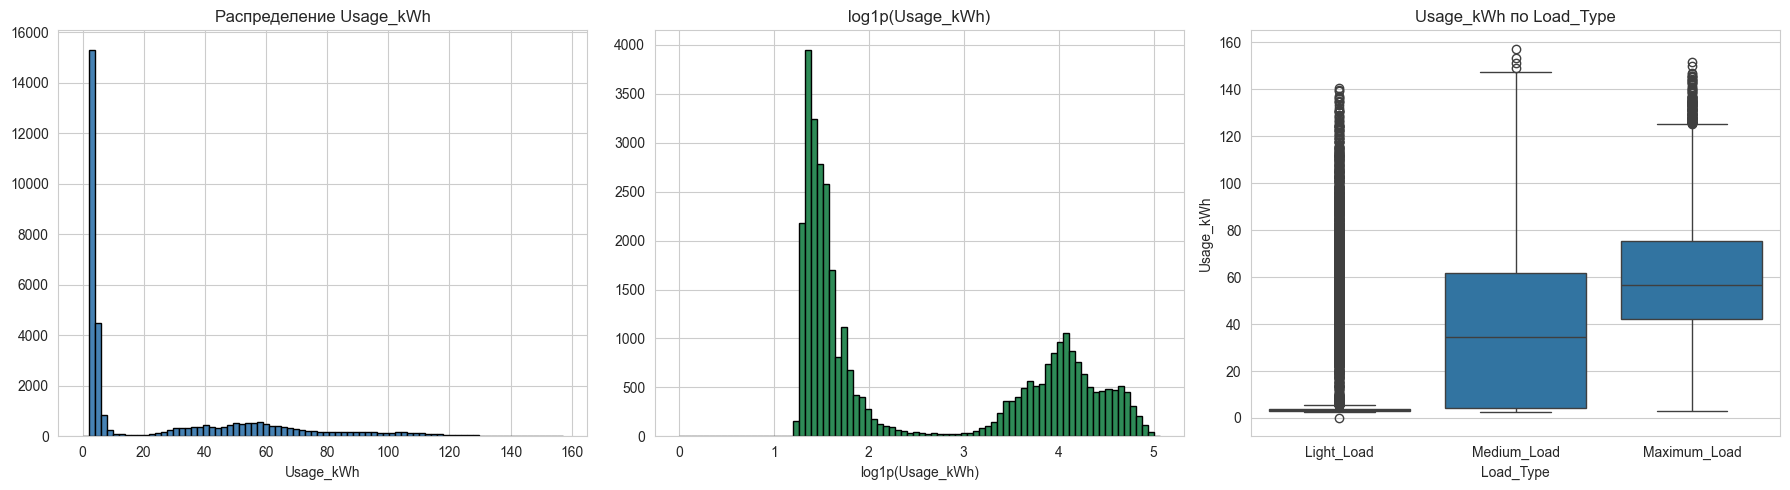

Skew: 1.1973938227692205
Kurtosis: 0.391385601423929
Доля > 100 кВт·ч: 0.04800228310502283


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Гистограмма
axes[0].hist(df['Usage_kWh'], bins=80, color='steelblue', edgecolor='black')
axes[0].set_title("Распределение Usage_kWh")
axes[0].set_xlabel("Usage_kWh")

# 2) Лог-гистограмма
axes[1].hist(np.log1p(df['Usage_kWh']), bins=80, color='seagreen', edgecolor='black')
axes[1].set_title("log1p(Usage_kWh)")
axes[1].set_xlabel("log1p(Usage_kWh)")

# 3) Boxplot по Load_Type
sns.boxplot(data=df, x='Load_Type', y='Usage_kWh', ax=axes[2])
axes[2].set_title("Usage_kWh по Load_Type")

plt.tight_layout()
save(fig, "01_target_distribution")
plt.show()

# Скошенность и эксцесс
print("Skew:", df['Usage_kWh'].skew())
print("Kurtosis:", df['Usage_kWh'].kurt())
print("Доля > 100 кВт·ч:", (df['Usage_kWh'] > 100).mean())

Диаграмма "Распределение Usage_kWh":

Огромный "столб" слева почти у нуля (около 3-5 кВт·ч) и длинный плоский "хвост" вправо до 160.

Выводы:
- Завод работает в двух основных состояниях. Либо он не работает (около 15 000 раз за год потребление было минимальным), либо работает с переменной нагрузкой.
- Цифры: Skew = 1.19 (асимметрия). Для идеального распределения ("колокол") Skew равен 0. У нас 1.19 — сильный перекос вправо.
- Доля значений мощности > 100 кВт·ч: всего 0.005% (или 0.48% от всех данных). Редкие, но значимые пики.


Логарифмическое распределение log(Usage_kWh)
- Взяли логарифм от Usage_kWh. Вместо одного столба у нуля получилось два "горба" (две вершины).
- Логарифм раздвинул данные. Теперь мы четко видим два режима работы завода:
    - Левый горб (около 1.5) — это завод на минимальной мощности.
    - Правый горб (около 4.5) — это завод на высокой мощности.
Вывод: Логарифмирование помогает модели лучше "увидеть" разницу между режимами, поэтому надо использовать log1p(Usage_kWh) как цель для обучения.


"Ящик с усами" (Boxplot по Load_Type)
- Light_Load (Небольшая нагрузка): Почти все значения прижаты к нулю (ящик очень низкий). Но есть много выбросов (черные точки), которые улетают вверх до 140.
Это значит, что даже когда система ставит статус Light_Load, иногда завод потребляет энергию как при максимальной нагрузке! То есть Load_Type — это не строгий показатель, а просто метка, которую иногда ставят с ошибкой.
- Medium_Load (Средняя нагрузка): Ящик широкий (от 10 до 60). Небольшое количество выбросов
- Maximum_Load (Максимальная нагрузка): Ящик смещен вверх (от 40 до 75), значения выше, чем у остальных.
Вывод: Load_Type — полезный параметр, несмотря на выбросы, он действительно разделяет уровни потребления.


Итоговые заключения по анализу таргета:
1.	Распределение "двугорбое" и с сильным перекосом.
2.	Логарифм полезный инструмент: он показывает скрытую структуру (два режима работы).
3.	Load_Type работает.


### Оценка временной структуры

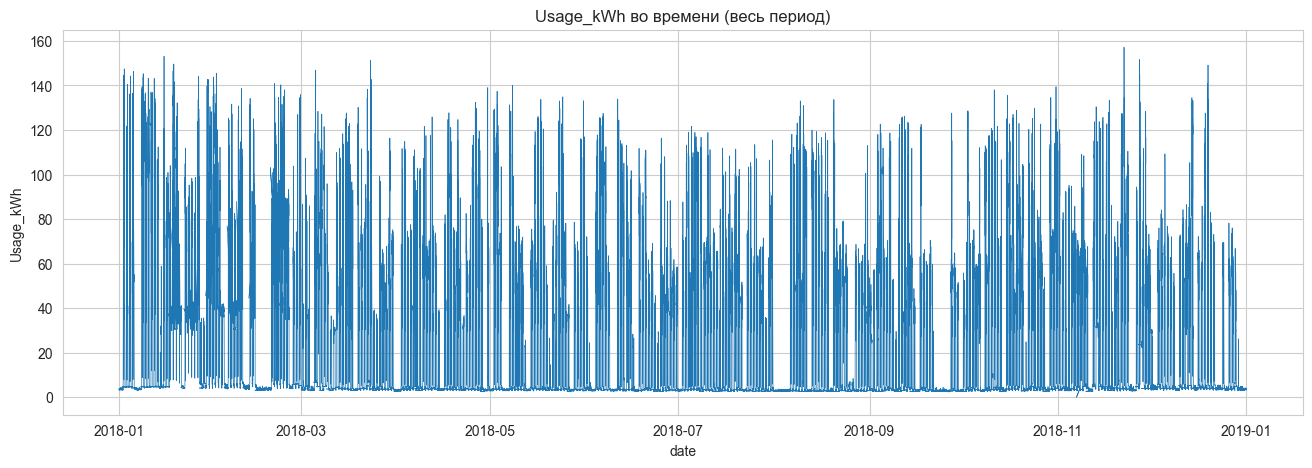

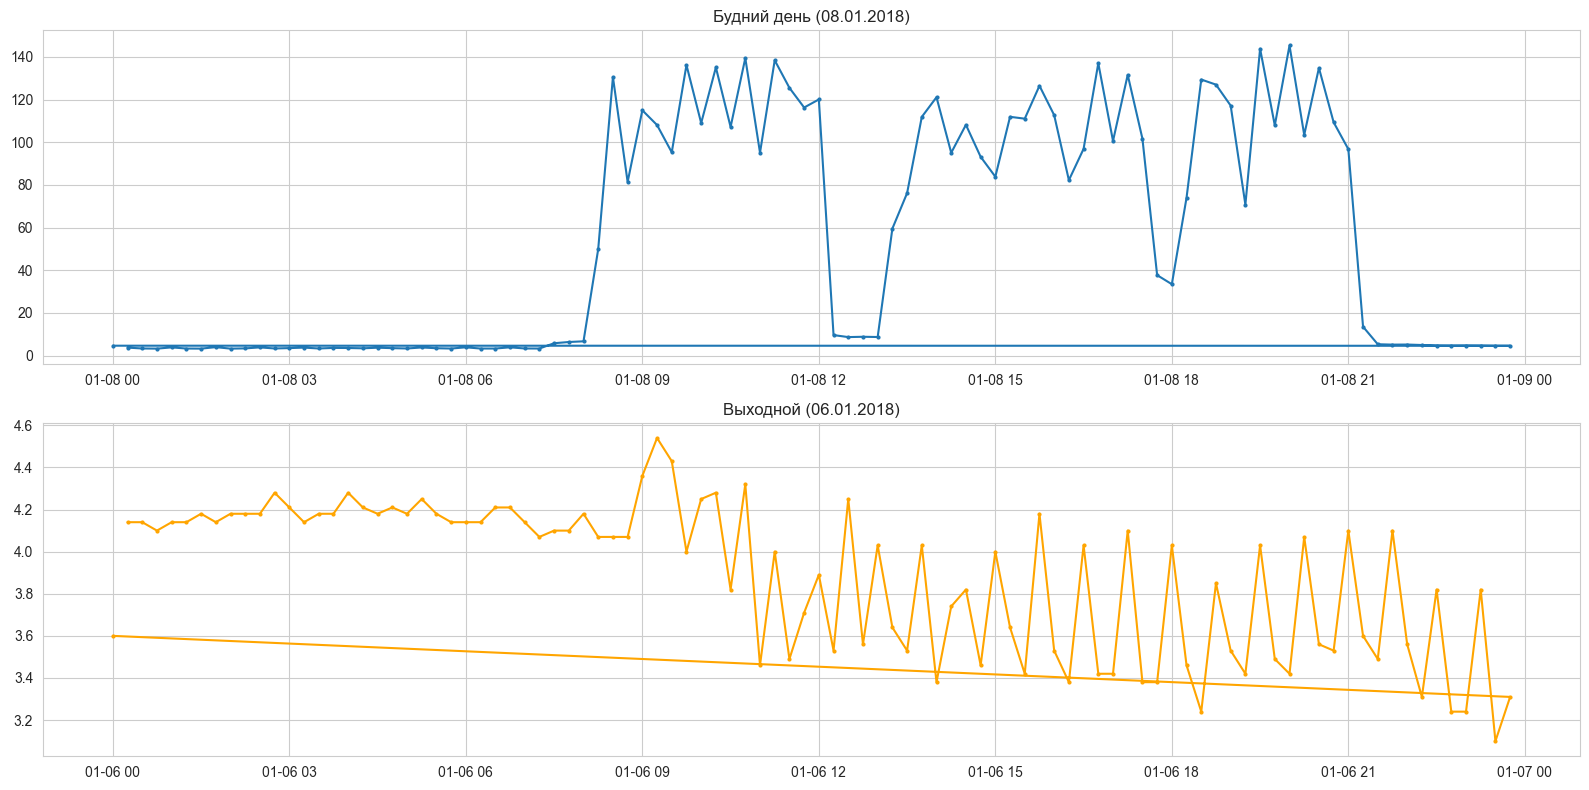

In [8]:
# Полный ряд
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df['date'], df['Usage_kWh'], linewidth=0.5)
ax.set_title("Usage_kWh во времени (весь период)")
ax.set_xlabel("date")
ax.set_ylabel("Usage_kWh")
save(fig, "02_full_timeseries")
plt.show()

# Один типичный будний день и один выходной для наглядности
sample_weekday = df[(df['date'] >= '2018-01-08') & (df['date'] < '2018-01-09')]
sample_weekend = df[(df['date'] >= '2018-01-06') & (df['date'] < '2018-01-07')]

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=False)
axes[0].plot(sample_weekday['date'], sample_weekday['Usage_kWh'], marker='o', ms=2)
axes[0].set_title("Будний день (08.01.2018)")
axes[1].plot(sample_weekend['date'], sample_weekend['Usage_kWh'], marker='o', ms=2, color='orange')
axes[1].set_title("Выходной (06.01.2018)")
plt.tight_layout()
save(fig, "03_weekday_vs_weekend")
plt.show()

## Общие выводы
1. График за весь год (синий, длинный)

Завод "дышит" как пульс. Есть четкие циклы: днем — всплески (до 150), ночью — падения почти до нуля.
Сезонность: в январе-марте и ноябре-декабре всплески более частые и высокие, чем в летние месяцы (июнь-август). Вероятно, зимой завод работает интенсивнее (или это связано с отопительным сезоном/технологическим процессом).
Вывод: У нас есть ярко выраженная суточная и сезонная цикличность. Модели обязательно нужны признаки времени (час, месяц, лаги).


2. Будний день (08.01.2018)

Ночью (с 00:00 до 08:00) ровная линия около 5 кВт·ч. Ровно в 08:00 происходит резкий скачок до ~130 кВт·ч. Днем — рваный график (завод то сбавляет, то набирает мощность). Вечером в 21:00 — резкий спад обратно к 5.
Это значит, что завод работает в одну смену (или основной цикл начинается утром). Ночью работают только дежурные системы (освещение, охрана, малые насосы). Днем — полноценное производство.
Вывод: Признаки "час суток" и лаги (данные за прошлые 15 минут, час, сутки) являются выгодными фичами.

3. Выходной день (06.01.2018)

Ночью (с 00 до 09 утра) значения выше (около 4.0-4.5), чем в будний день. Утром 06.01 (это суббота) есть легкий всплеск, но он гораздо ниже, чем в будни. Весь день график "пилообразный", но пики невысокие.
Это означает, что в выходные завод не работает на полную мощность. Возможно, ведутся регламентные работы, либо он работает не в полную силу. Ночью фоновая нагрузка чуть выше, чем в будни (возможно, особенности работы персонала или оборудования).


Получается, что

1.	Суточный цикл — главный. У нас есть четкое "расписание": ночь — минимум, день — максимум.
2.	Будни и выходные сильно отличаются. Признаки is_weekend и Day_of_week будут очень полезны.
3.	Есть сезонность. Зима и лето могут отличаться, нужно добавить признак month (месяц).

## Профили по часам и дням недели

NSM совпадает с hour*3600+minute*60 в 100.0 % строк


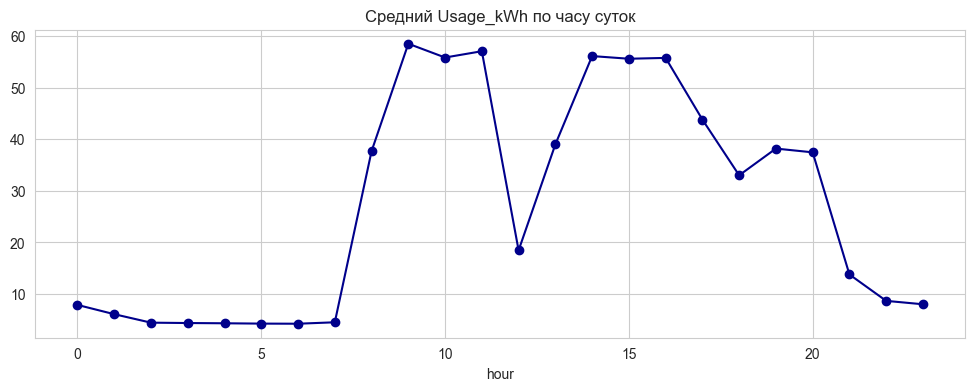

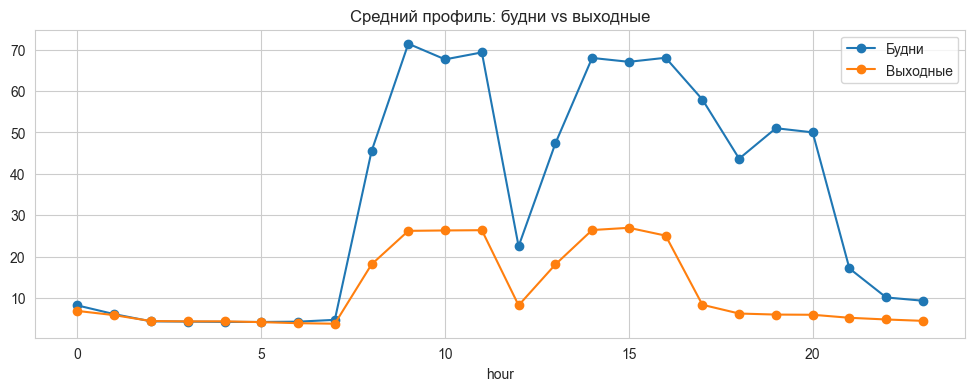

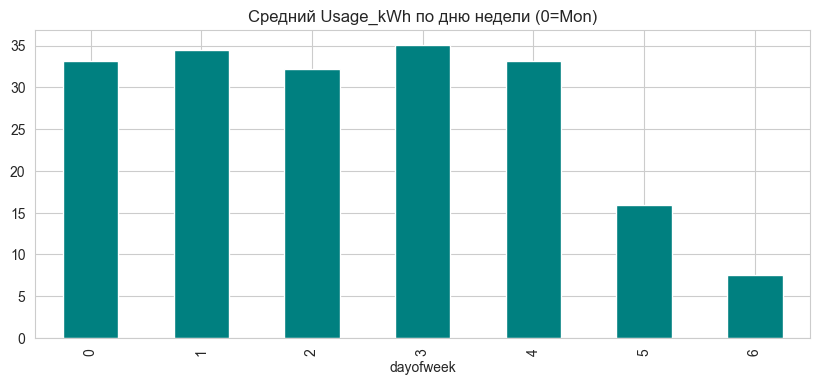

In [9]:
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df['dayofweek'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day

# Проверим NSM: должен равняться hour*3600 + minute*60
df['NSM_check'] = df['hour']*3600 + df['minute']*60
print("NSM совпадает с hour*3600+minute*60 в",
      (df['NSM'] == df['NSM_check']).mean()*100, "% строк")

# Средний профиль по часу суток
fig, ax = plt.subplots(figsize=(12, 4))
df.groupby('hour')['Usage_kWh'].mean().plot(ax=ax, marker='o', color='darkblue')
ax.set_title("Средний Usage_kWh по часу суток")
ax.set_xlabel("hour")
save(fig, "04_hourly_profile")
plt.show()

# Профиль будни vs выходные
fig, ax = plt.subplots(figsize=(12, 4))
for w, label in [(0, 'Будни'), (1, 'Выходные')]:
    df[df['is_weekend']==w].groupby('hour')['Usage_kWh'].mean().plot(
        ax=ax, marker='o', label=label)
ax.set_title("Средний профиль: будни vs выходные")
ax.legend()
save(fig, "05_weekday_weekend_profile")
plt.show()

# Средний Usage по дням недели
fig, ax = plt.subplots(figsize=(10, 4))
df.groupby('dayofweek')['Usage_kWh'].mean().plot(kind='bar', ax=ax, color='teal')
ax.set_title("Средний Usage_kWh по дню недели (0=Mon)")
save(fig, "06_dayofweek_profile")
plt.show()

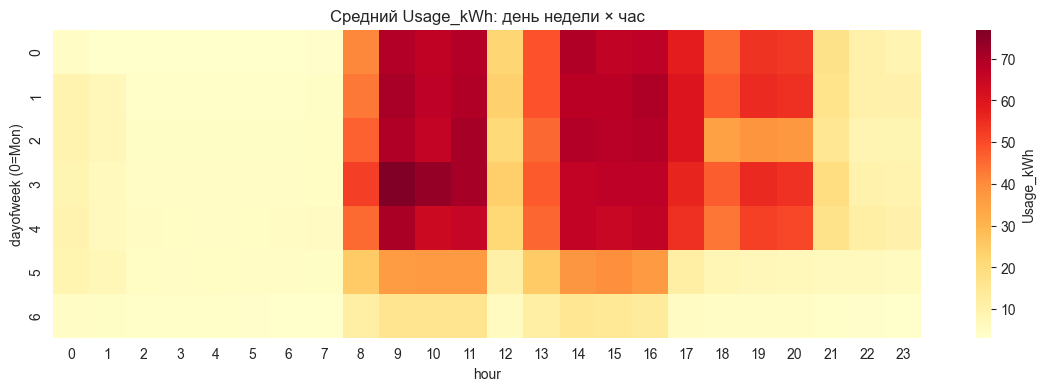

In [10]:
pivot = df.pivot_table(index='dayofweek', columns='hour',
                       values='Usage_kWh', aggfunc='mean')
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={'label': 'Usage_kWh'})
ax.set_title("Средний Usage_kWh: день недели × час")
ax.set_xlabel("hour"); ax.set_ylabel("dayofweek (0=Mon)")
save(fig, "07_heatmap_day_hour")
plt.show()

Средний профиль по часу (верхний график)
-	Ночью (с 23:00 до 7:00): Завод практически стоит, потребление около 5 кВт·ч.
-	Утром (с 8:00): Резкий старт. В 8 утра потребление подскакивает до ~40, в 9 — до 60.
-	Обед (12:00): Интересный «провал» — потребление падает с 60 до 20 (обеденный перерыв)! Предприятие останавливается (или работает не на полную).
-	После обеда (13:00 – 16:00): Снова пик до 55–56. Основная рабочая смена.
-	Вечер (с 17:00): Постепенный спад. В 21:00 — снова резкое падение (предприятие закрывается).
Вывод: У нас есть четкий производственный цикл с обеденным перерывом. Получается, что модель должна знать не только час, но и минуту, чтобы "ловить" резкие падения в 12:00.

2. Будни vs Выходные (средний график)
-	Будни (синяя линия): Огромные пики, четкий обеденный провал, вечерний спад.
-	Выходные (оранжевая линия): График гораздо ниже и ровнее. Пики не превышают 30. Обеденного провала почти нет (момент работы только дежурной смены).
Вывод: Выходные — это другой режим работы. Модель должна обязательно знать, выходной день или нет. Разница между буднями и выходными очень значительная!

3. Средний профиль по дням недели (столбики)
-	Пн–Пт: Высокая нагрузка (около 33–35).
-	Суббота: Нагрузка падает вдвое (16).
-	Воскресенье: Самая низкая нагрузка (около 8). Завод почти полностью отдыхает.
Вывод: Подтверждается, что недельный цикл очень важен.

4. Тепловая карта (Heatmap — самый наглядный график)
-	Оси: Вертикальная — дни недели (0 — понедельник, 6 — воскресенье). Горизонтальная — часы суток (0–23).
-	Цвета: Темно-красный — максимальная нагрузка, светло-желтый — минимальная.
Наблюдения
-	Огромное темное пятно в будни с 9 до 17 часов (момент максимальной нагрузки).
-	Выходные дни (5 и 6) почти полностью желтые, кроме небольшого потемнения днем.
-	В будни есть белая вертикальная полоса ровно на 12 часах (обеденный перерыв).
-	В понедельник (0) в 11 утра и в четверг (3) в 10 утра пятна темнее всего — возможно, в эти дни самые большие производственные планы.

Общий итог

1.	Суточная и недельная сезонность — важные показатели.
2.	Обеденный перерыв — важная деталь, которую нужно учитывать при создании модели.


## Реактивная мощность

Построим графики рассеяния (Scatter) и корреляционную матрицу. Увидим, насколько сильно реактивы связаны с потреблением энергии и подтвердим догадку про CO2.

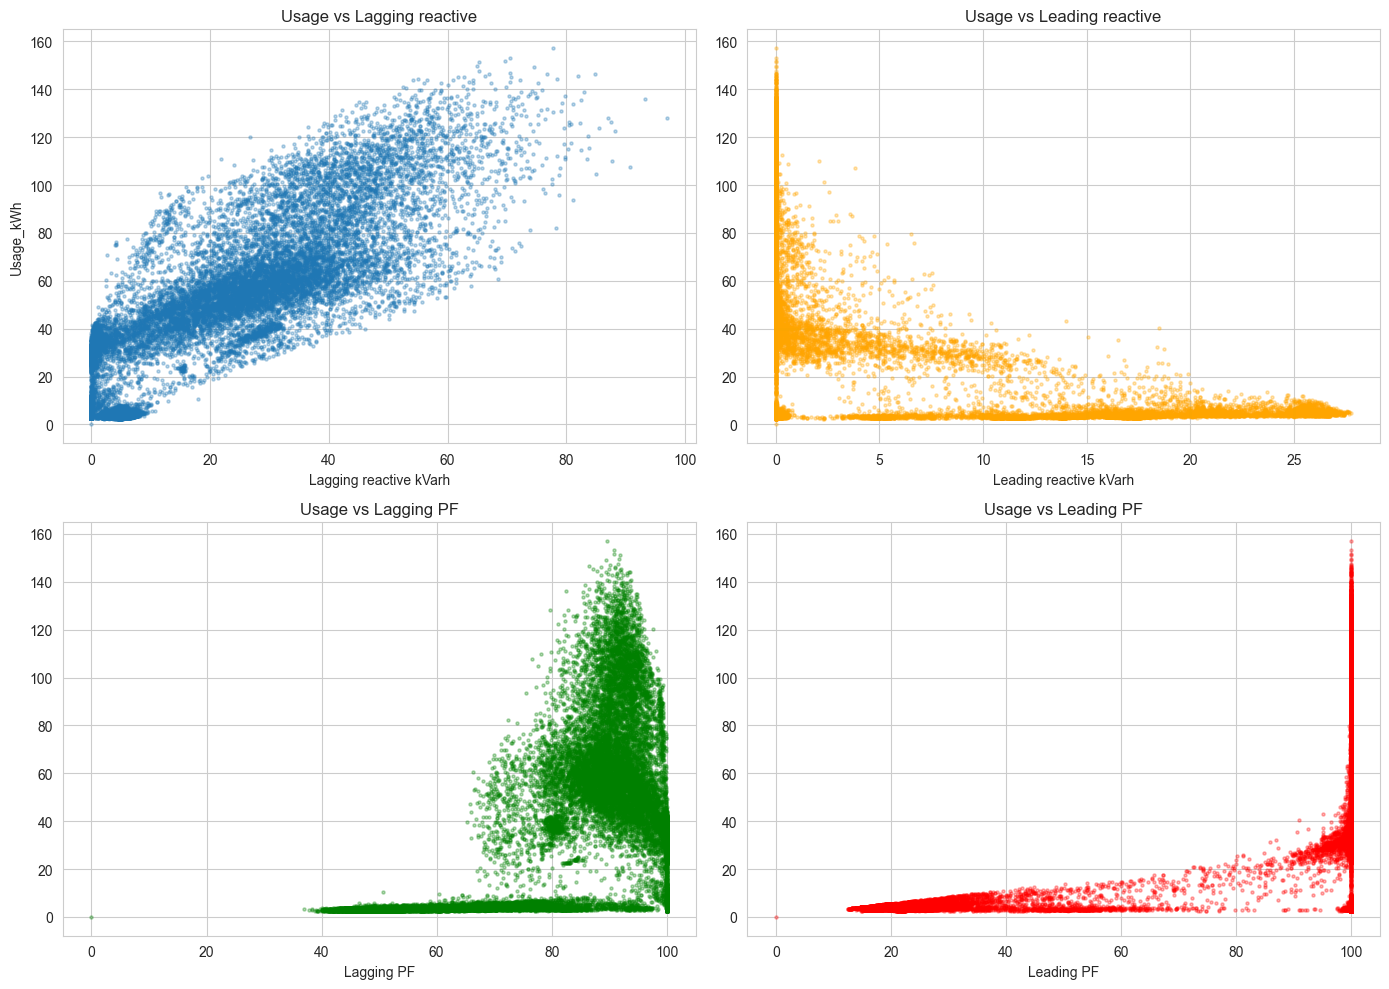

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Usage vs Lagging reactive
axes[0,0].scatter(df['Lagging_Current_Reactive.Power_kVarh'], df['Usage_kWh'],
                  s=5, alpha=0.3)
axes[0,0].set_xlabel("Lagging reactive kVarh")
axes[0,0].set_ylabel("Usage_kWh")
axes[0,0].set_title("Usage vs Lagging reactive")

# Usage vs Leading reactive
axes[0,1].scatter(df['Leading_Current_Reactive_Power_kVarh'], df['Usage_kWh'],
                  s=5, alpha=0.3, color='orange')
axes[0,1].set_xlabel("Leading reactive kVarh")
axes[0,1].set_title("Usage vs Leading reactive")

# Usage vs Lagging PF
axes[1,0].scatter(df['Lagging_Current_Power_Factor'], df['Usage_kWh'],
                  s=5, alpha=0.3, color='green')
axes[1,0].set_xlabel("Lagging PF")
axes[1,0].set_title("Usage vs Lagging PF")

# Usage vs Leading PF
axes[1,1].scatter(df['Leading_Current_Power_Factor'], df['Usage_kWh'],
                  s=5, alpha=0.3, color='red')
axes[1,1].set_xlabel("Leading PF")
axes[1,1].set_title("Usage vs Leading PF")

plt.tight_layout()
save(fig, "08_reactive_scatter")
plt.show()

### Графики рассеяния (Scatter plots)
Слева сверху (Синий): Usage vs Lagging reactive
- Наблюдения: Четкая диагональная полоса снизу слева вверх направо.
- Вывод: Чем больше активная мощность (Usage_kWh), тем больше запаздывающая реактивная мощность (Lagging). Это очень сильная и прямая зависимость. Завод потребляет их вместе. Это наш главный признак. Если мы знаем Lagging, мы уже можем неплохо предположить Usage.

Справа сверху (Оранжевый): Usage vs Leading reactive
- Наблюдения: Огромный столб у нуля, который резко падает. Есть «хвост» вправо, но там Usage низкий (до 60).
- Вывод: Опережающая реактивная мощность (Leading) — это, по сути, «выключатель». Она либо равна нулю (завод работает в обычном режиме), либо включается на полную (завод компенсирует реактивную энергию). При этом, когда Leading высокий, активная мощность обычно низкая (до 60). Это режимный признак, а не прямая зависимость.

Слева снизу (Зеленый): Usage vs Lagging PF
- Наблюдения: Перевернутая «запятая». Значения сгруппированы: основная масса при PF > 60, но есть полоса внизу при PF близком к 0, и «хвост» уходит вверх до 160 при PF = 100.
- Вывод: Когда коэффициент мощности (PF) высокий (близкий к 100), завод может работать на любой мощности (от 0 до 160). Когда PF низкий, завод работает только на минимальной мощности. Низкий PF = завод почти стоит. Для модели это тоже очень важный признак.

Справа снизу (Красный): Usage vs Leading PF
- Наблюдения: Почти все точки прижаты к 100. Есть только узкая полоска внизу (PF от 0 до 40).
- Вывод: Коэффициент опережающего PF почти всегда 100. Он полезен только в те редкие моменты (ночью или в выходные), когда работает компенсация.


## Корреляционные матрицы (Heatmaps)

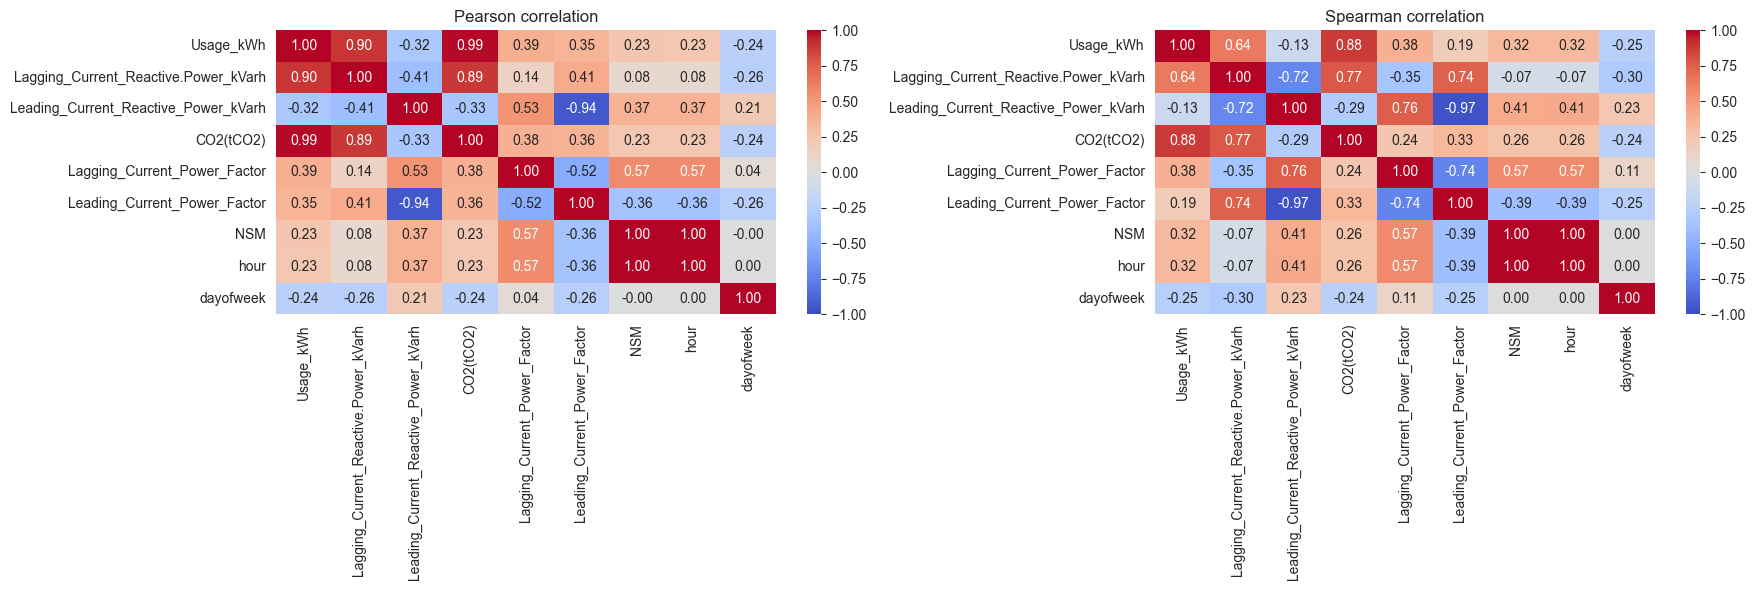


Наиболее важные по |Spearman|:
 CO2(tCO2)                               0.881514
Lagging_Current_Reactive.Power_kVarh    0.644937
Lagging_Current_Power_Factor            0.375158
NSM                                     0.322180
hour                                    0.322088
dayofweek                               0.250388
Leading_Current_Power_Factor            0.193501
Leading_Current_Reactive_Power_kVarh    0.131703
Name: Usage_kWh, dtype: float64


In [13]:
num_cols_all = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
                'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
                'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor',
                'NSM', 'hour', 'dayofweek']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(df[num_cols_all].corr(method='pearson'), annot=True, fmt=".2f",
            cmap='coolwarm', ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Pearson correlation")
sns.heatmap(df[num_cols_all].corr(method='spearman'), annot=True, fmt=".2f",
            cmap='coolwarm', ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Spearman correlation")
plt.tight_layout()
save(fig, "09_correlation_matrix")
plt.show()

# Топ признаков по |Spearman| с таргетом
target_corr = df[num_cols_all].corr(method='spearman')['Usage_kWh'].drop('Usage_kWh')
print("\nНаиболее важные по |Spearman|:\n", target_corr.abs().sort_values(ascending=False))

### Выводы:
1.	CO2 — 0.88:
Спирмен 0.88 — очень высокая корреляция. А по Пирсону — 0.99! Это подтверждает догадку: CO2 — это просто пересчитанная активная мощность. Если мы оставим его в модели, она просто выучит формулу CO2 = f(Usage). В реальной жизни на момент прогноза мы не знаем CO2. Выкидываем CO2 из признаков!
2.	Lagging reactive — 0.64:
Главный физический признак. Связь сильная и логичная. Оставляем.
3.	hour и NSM — 0.32:
Время суток имеет умеренную связь. Это подтверждает, что суточный цикл важен. Оставляем.
4.	Взаимная корреляция признаков (мультиколлинеарность):
-	Есть связь Lagging_Current_Power_Factor и Leading_Current_Power_Factor — она -0.74 по Спирмену. Это значит.
-	NSM и hour связаны на 0.57. Это логично — NSM (секунды от начала суток) и час суток — почти одно и то же. Для линейных моделей это может быть проблемой, значит, можно использовать деревья (Random Forest, XGBoost).


Получается, что:
1.	CO2 — это утечка. Убираем из признаков.
2.	Lagging reactive — самый важный признак.
3.	Lagging PF и Leading PF — режимные индикаторы. Когда PF падает, завод стоит.
4.	Время (hour, NSM) — важно. Цикличность подтверждена.


## Критический анализ CO2

Доля строк с CO2=0 при Usage>0: 59.90%


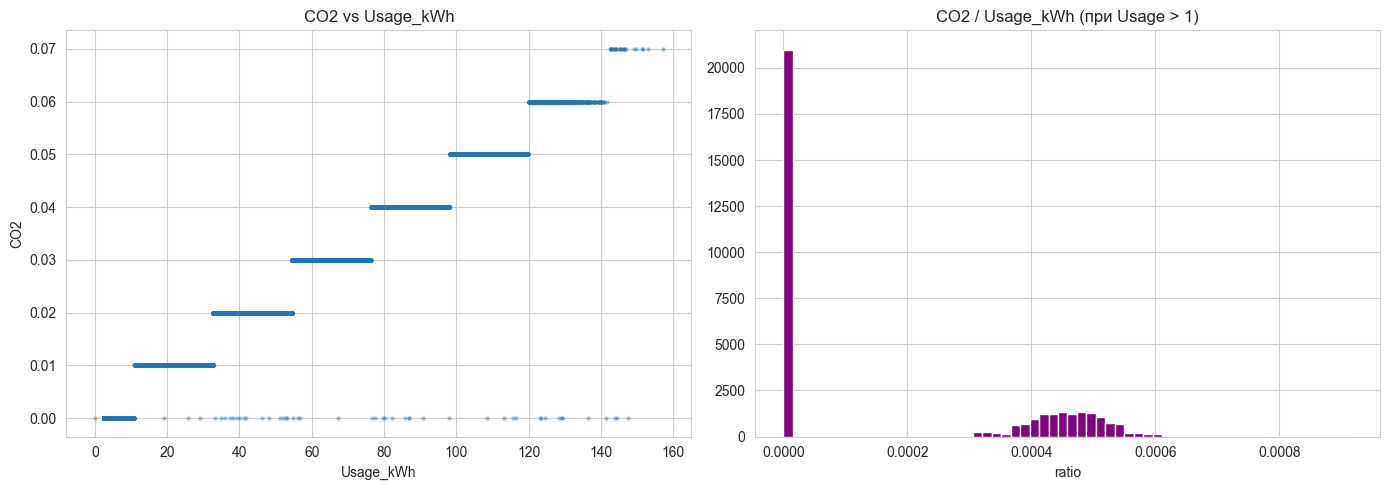

CO2/Usage: mean=0.00019, std=0.00023
Spearman CO2 vs Usage: 0.881513949180869


In [14]:
# 1) Scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(df['Usage_kWh'], df['CO2(tCO2)'], s=5, alpha=0.3)
axes[0].set_xlabel("Usage_kWh"); axes[0].set_ylabel("CO2")
axes[0].set_title("CO2 vs Usage_kWh")

# 2) Доля нулей CO2 при ненулевом Usage
zero_co2_share = ((df['CO2(tCO2)'] == 0) & (df['Usage_kWh'] > 0)).mean()
print(f"Доля строк с CO2=0 при Usage>0: {zero_co2_share*100:.2f}%")

# 3) Проверим: CO2 / Usage — константа?
mask = df['Usage_kWh'] > 1
ratio = df.loc[mask, 'CO2(tCO2)'] / df.loc[mask, 'Usage_kWh']
axes[1].hist(ratio, bins=60, color='purple')
axes[1].set_title("CO2 / Usage_kWh (при Usage > 1)")
axes[1].set_xlabel("ratio")
plt.tight_layout()
save(fig, "10_co2_leak")
plt.show()

print("CO2/Usage: mean=%.5f, std=%.5f" % (ratio.mean(), ratio.std()))
print("Spearman CO2 vs Usage:",
      stats.spearmanr(df['CO2(tCO2)'], df['Usage_kWh']).correlation)

1. Левый график: CO2 vs Usage_kWh
-	Наблюдения: Данные выстроены в идеальные горизонтальные полоски-ступеньки. CO2 принимает всего несколько значений: 0.00, 0.01, 0.02... до 0.07.
- Вывод: CO2 здесь не измеряется физическим датчиком (иначе точки были бы разбросаны облаком). Это просто математический расчет. Usage_kWh умножают на какой-то коэффициент и округляют до двух знаков после запятой (до сотых). Поэтому при Usage=20 CO2 всегда 0.01, а при Usage=50 всегда 0.03.

2. Доля строк с CO2=0 при Usage>0: 59.90%
- Наблюдения: В 60% случаев завод потребляет энергию, но CO2 записан как 0. Это округление. Если Usage = 3, то коэффициент дает, например, 0.0009, и при округлении до сотых это превращается в 0.00.
- Вывод: Это мусорный признак с округлением.

3. Правый график: CO2 / Usage_kWh
- Наблюдения: Огромный столб у нуля (из-за тех самых нулей) и маленькое облачко сбоку: mean=0.00019, std=0.00023.
- Вывод: Отношение CO2 к Usage почти константа. Это еще раз доказывает, что CO2 — это производная от энергии.


### Общее заключение по CO2:
Удаляем его из признаков

## Промежуточные выводы:

1.	Данные чистые, без пропусков.
2.	Есть четкая суточная, недельная и сезонная цикличность (графики "пульса").
3.	Обеденный перерыв (12:00) — важная особенность.
4.	Главный признак — Lagging_Current_Reactive.Power_kVarh.
5.	Load_Type и PF работают как режимные переключатели.
6.	CO2 — выкидываем.


## Проверка физики переключения режимов (Lagging/Leading)

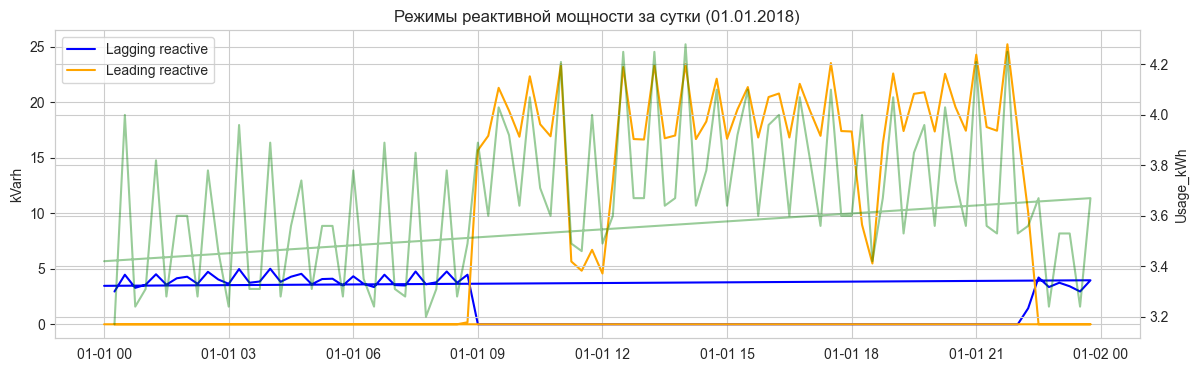

In [15]:
# Посмотрим на сутки, где есть переключение режимов (01.01.2018)
sample = df[(df['date'] >= '2018-01-01') & (df['date'] < '2018-01-02')]

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(sample['date'], sample['Lagging_Current_Reactive.Power_kVarh'],
         label='Lagging reactive', color='blue')
ax1.plot(sample['date'], sample['Leading_Current_Reactive_Power_kVarh'],
         label='Leading reactive', color='orange')
ax1.set_ylabel("kVarh")
ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.plot(sample['date'], sample['Usage_kWh'], color='green', alpha=0.4,
         label='Usage_kWh')
ax2.set_ylabel("Usage_kWh")
ax1.set_title("Режимы реактивной мощности за сутки (01.01.2018)")
save(fig, "11_reactive_modes")
plt.show()

Левая ось (kVarh) и две линии:
-	Синяя линия (Lagging reactive): Держится примерно на уровне 4-5 ночью. Ровно в 09:00 утра она падает до нуля и лежит на нуле до самого вечера (до ~22:00).
-	Оранжевая линия (Leading reactive): Ночью лежит на нуле. Ровно в 09:00 утра она резко скачет вверх (до 15-20) и остается высокой весь день, покачиваясь вверх-вниз. Вечером в 22:00 падает обратно в ноль.
-	Зеленая линия (Usage_kWh, правая ось): Это наше потребление энергии. Она показывает, что днем завод работает (пики, обеденный провал), а ночью стоит.
Выводы:
1.	Два режима работы завода:
-	Ночной режим (завод спит): Работают только базовые системы. Им нужна небольшая запаздывающая реактивная мощность (синяя линия). Опережающей (оранжевой) нет вообще.
-	Дневной режим (завод работает): Включаются мощные станки. И тут происходит магия: завод (или его автоматика) включает компенсирующие конденсаторы (батареи). Они начинают вырабатывать опережающую реактивную мощность (оранжевая линия), чтобы скомпенсировать ту, которую потребляют станки. Поэтому синяя линия падает в ноль, а оранжевая растет.

2.	Значение для нашей задачи:
-	Время суток (09:00 и 22:00) — это ключ к пониманию реактивной мощности.
-	Если просто указать модели "Lagging = 0", модель интерпретирует это как остановку предприятия, хотя на самом деле работа ведется.
-	Поэтому обязательно нужно знать час суток, чтобы правильно интерпретировать нулевой показатель, поэтому нужны признаки hour (и NSM).

Общий вывод:
Мы подтвердили, что данные физически логичны. Завод переключает режимы компенсации. В наших признаках должны быть и Lagging, и Leading, и время суток.


### Календарные признаки

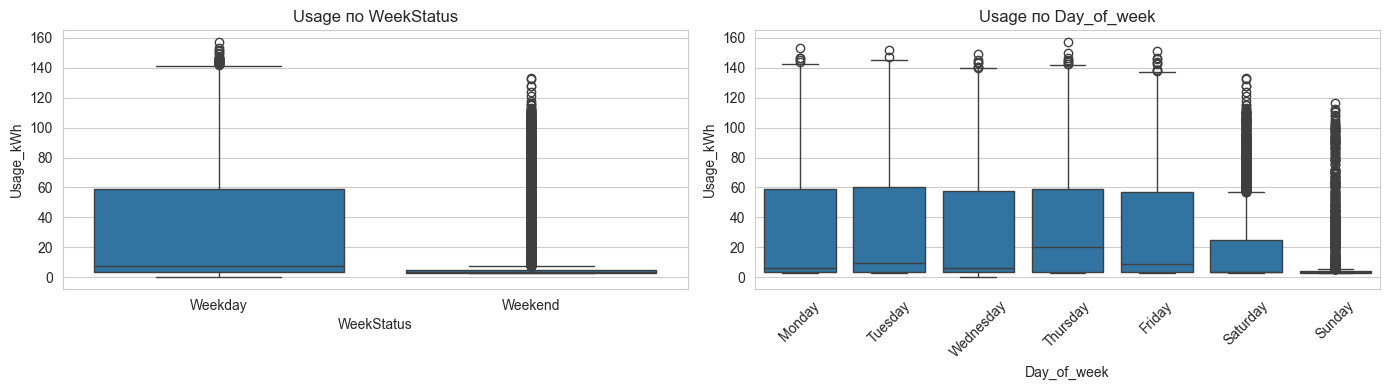

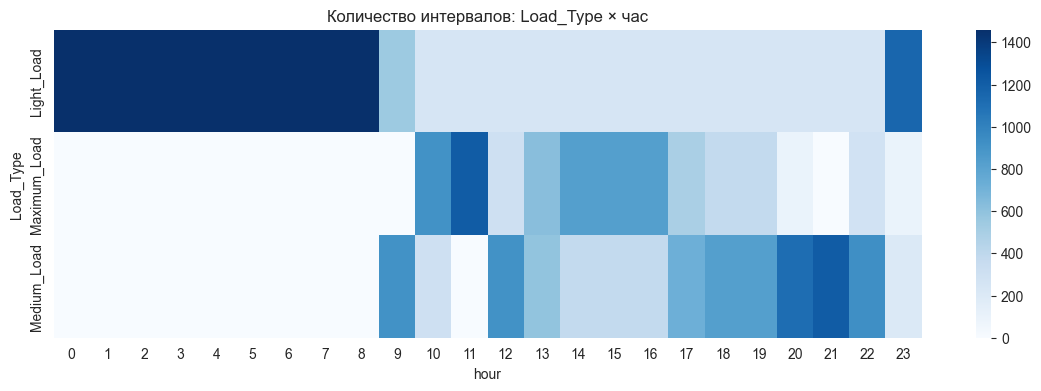

In [16]:
# Распределение по WeekStatus
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x='WeekStatus', y='Usage_kWh', ax=axes[0])
axes[0].set_title("Usage по WeekStatus")
sns.boxplot(data=df, x='Day_of_week', y='Usage_kWh', ax=axes[1])
axes[1].set_title("Usage по Day_of_week")
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
save(fig, "12_calendar_boxplots")
plt.show()

# Распределение Load_Type по часам
pivot_lt = df.pivot_table(index='Load_Type', columns='hour',
                          values='Usage_kWh', aggfunc='count').fillna(0)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot_lt, cmap="Blues", ax=ax)
ax.set_title("Количество интервалов: Load_Type × час")
save(fig, "13_loadtype_hour")
plt.show()

1. Будни vs Выходные (верхний левый)
-	Будни (Weekday): Ящик очень высокий (от ~10 до ~60). Это значит, что в будни нагрузка сильно варьируется, завод работает активно.
-	Выходные (Weekend): Ящик сплющен в тонкую линию у самого нуля. Завод практически стоит.
-	Вывод: Признак выходного дня (is_weekend) — сильный признак для модели.

2. По дням недели (верхний правый)
-	Пн–Пт: Все ящики одинаково высокие, полны выбросов. Завод работает.
-	Суббота: Ящик ниже, но есть длинный «хвост» выбросов. В субботу иногда бывают авралы (пусконаладка, сверхурочные).
-	Воскресенье: Самый низкий ящик, почти не работает.
-	Вывод: День недели тоже важен, особенно выделяется суббота (переходный режим).

3. Heatmap Load_Type × Час (нижний)
Этот график показывает, сколько раз за год системе присваивался тот или иной тип нагрузки в конкретный час.
-	Light_Load (Легкая): Темно-синий цвет ночью (с 0 до 8) и вечером (с 23). Это логично: ночью завод не работает, нагрузка легкая.
-	Medium_Load (Средняя): Появляется с 9 утра и держится до вечера. Пик приходится на 19–22 часа.
-	Maximum_Load (Максимальная): Почти не встречается ночью. Появляется в 9 утра, но самые темные пятна — это 15–16 часов и 20–22 часа.
Вывод:
Тип нагрузки (Load_Type) — это не случайная метка. Она привязана ко времени суток, при этом в 12 часов дня (обед) на графике Maximum_Load становится светло-голубым (нагрузка падает). Значит, система корректно понимает, что в обед станки останавливаются.


### Итоговые выводы:
1.	Выходные и будни отличаются.
2.	Load_Type — полезный признак, он коррелирует со временем суток и реальным потреблением.


## Аномалии и выбросы

In [17]:
# IQR по Usage
Q1, Q3 = df['Usage_kWh'].quantile([0.25, 0.75])
IQR = Q3 - Q1
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = df[(df['Usage_kWh'] < low) | (df['Usage_kWh'] > high)]
print(f"IQR-границы: [{low:.2f}, {high:.2f}], выбросов: {len(outliers)} "
      f"({len(outliers)/len(df)*100:.2f}%)")

# Где эти выбросы по часу?
print(outliers['hour'].value_counts().sort_index())

# Проверим даты-аномалии: сильно ниже среднего
daily_mean = df.groupby(df['date'].dt.date)['Usage_kWh'].mean()
print("\nТоп-5 самых низких дней:\n", daily_mean.nsmallest(5))
print("\nТоп-5 самых высоких дней:\n", daily_mean.nlargest(5))

IQR-границы: [-68.86, 123.29], выбросов: 328 (0.94%)
hour
8     12
9     46
10    39
11    41
12    11
13    22
14    26
15    34
16    32
17    23
18    13
19    19
20    10
Name: count, dtype: int64

Топ-5 самых низких дней:
 date
2018-09-26    2.702708
2018-10-07    2.752396
2018-09-25    2.755521
2018-09-30    2.763125
2018-09-23    2.785833
Name: Usage_kWh, dtype: float64

Топ-5 самых высоких дней:
 date
2018-01-18    76.602500
2018-01-19    74.740625
2018-01-26    73.638437
2018-02-22    64.179167
2018-01-31    63.973333
Name: Usage_kWh, dtype: float64


Посчитаем, сколько у нас «пиков» (выбросов) и в какие часы они происходят. А также посмотрим на самые «тихие» и самые «жаркие» дни в году.

1. IQR-границы и выбросы
-	Границы: [-68.86, 123.29]. Так как потребление не может быть отрицательным, нижняя граница нам не важна. Верхняя — 123.29.
-	Выбросов: 328 (0.94%). Это меньше 1% от всех данных.
-	Выводы: Если завод потребляет больше 123.29 кВт·ч, это считается это выбросом. Но это реальные пики (максимум был 157). Их не удаляем: их мало, и они редкие.

2. Распределение выбросов по часам
-	Топ часов: 9 утра (46 раз), 11 утра (41), 10 утра (39), 8 утра (12).
-	Что это значит: Пики происходят почти исключительно в рабочее время (с 8 до 17 часов). В 8 утра — запуск производства, в 9-11 — работа на максимальных мощностях. Ночью выбросов почти нет.
-	Вывод: Выбросы — это не ошибки датчика. Это реальные производственные максимумы. Модель должна знать, что утром бывают высокие пики.

3. Топ-5 самых "тихих" дней (Lowest)
-	Даты: 26 сентября, 7 октября, 25 сентября, 30 сентября, 23 сентября.
-	Среднее: всего около 2.7 кВт·ч.
-	Что это значит: Сентябрь был очень тихим месяцем. Завод либо стоял на ремонте, либо выпускал мало продукции. Это важно, потому что показывает: в данных есть длительные периоды спада, и модель не должна паниковать, если она увидит такие периоды в тесте.

4. Топ-5 самых "жарких" дней (Highest)
-	Даты: 18 января, 19 января, 26 января, 22 февраля, 31 января.
-	Среднее: около 76 кВт·ч.
-	Что это значит: Вся первая половина года (январь-февраль) была очень загруженной. Это подтверждает догадку о сезонности (зимой завод работал больше, чем осенью). Признак month (месяц) будет полезен.


### Итоговые выводы
1.	Выбросы реальны. Мы их не удаляем. Модель должна учиться на них, чтобы предсказывать редкие пики.
2.	Пики привязаны к времени. Выбросы случаются с 8 до 17 часов. Это еще раз подтверждает силу признаков времени.
3.	Есть месяцы с низкой и высокой нагрузкой. Сентябрь — "спокойный", Январь — "жаркий".


## Проверка сезонности и стационарности

Графики ACF/PACF покажут, как сильно данные зависят от прошлых значений (например, от того, что было 15 минут назад, 1 час назад, 1 сутки назад). Далее запустим ADF-тест, который выдаст число p-value.

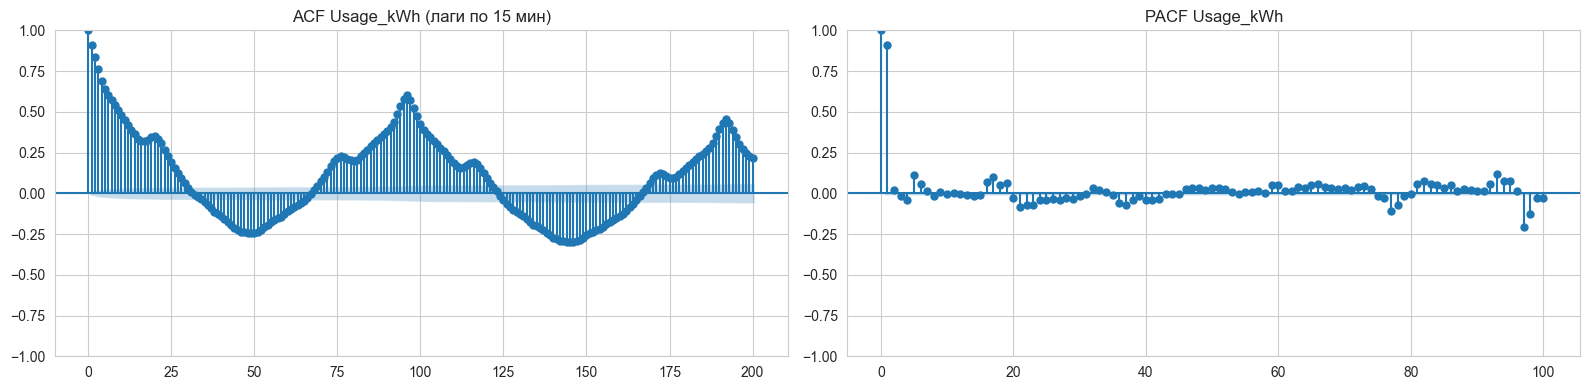

ADF statistic: -24.298, p-value: 0.0000
Вывод: стационарен


C:\Users\makar\AppData\Local\Temp\ipykernel_38808\2984783544.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series.dropna(), autolag='AIC')


In [18]:
# Возьмём непрерывный кусок (без пропусков) и построим ACF/PACF по лагам
series = df.set_index('date')['Usage_kWh'].asfreq('15min')

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(series.dropna(), lags=200, ax=axes[0])
axes[0].set_title("ACF Usage_kWh (лаги по 15 мин)")
plot_pacf(series.dropna(), lags=100, ax=axes[1], method='ywm')
axes[1].set_title("PACF Usage_kWh")
plt.tight_layout()
save(fig, "14_acf_pacf")
plt.show()

# ADF-тест
adf = adfuller(series.dropna(), autolag='AIC')
print(f"ADF statistic: {adf[0]:.3f}, p-value: {adf[1]:.4f}")
print("Вывод:", "стационарен" if adf[1] < 0.05 else "нестационарен (нужны лаги/разности)")

1. Левый график (ACF — Автокорреляция)
-	Что это: Показывает, насколько текущее потребление связано с тем, что было N шагов назад. По оси X — лаги (сдвиги по 15 минут), по оси Y — сила связи (от -1 до 1).
-	Наблюдения:
    В начале график плавно спускается вниз, уходит в минус (около лага 48 — это 12 часов), затем снова поднимается вверх.
    Главное: На лаге 96 (это ровно сутки, 24 часа × 4) мы видим четкий «горб» с коэффициентом около 0.6. И еще один «горб» на лаге 192 (это двое суток).
-	Что это значит: Потребление энергии очень сильно зависит от суточного цикла. То, что завод потребляет сейчас (в 15:00), сильно похоже на то, что он потреблял вчера в это же время. Это суточная сезонность.
2. Правый график (PACF — Частичная автокорреляция)
-	Что это: Показывает «чистую» связь, убирая влияние промежуточных шагов.
-	Что видим: Огромный столб на первом лаге (сдвиг на 15 минут) и мелкие всплески на лагах 4 (1 час) и 96 (сутки).
-	Что значит: Самая сильная связь — с предыдущим 15-минутным интервалом. Модель должна обязательно знать, сколько завод потреблял 15 минут назад. А также полезно знать, что было 1 час назад и ровно сутки назад.


### Итоги по ACF/PACF:
Графики говорят нам, какие признаки (лаги) нужно создать. Мы не можем дать модели просто «время», мы должны дать ей прошлые значения:
1.	Лаг 1 (15 минут назад): Usage_kWh.shift(1) — самое важное.
2.	Лаг 4 (1 час назад): Usage_kWh.shift(4) — чтобы видеть тренд.
3.	Лаг 96 (1 сутки назад): Usage_kWh.shift(96) — чтобы модель знала, что вчера в это же время было.
4.	Лаг 672 (1 неделя назад): Usage_kWh.shift(672) — так как у нас есть недельная сезонность (будни/выходные).


Получается, что суточная сезонность доказана. Интервал 96 (ровно сутки) — ключевой. Лаги обязательны. Модель без прошлых данных не сможет выдать нормальный прогноз.


## STL-декомпозиция

Разложим ряд на три составляющие: Тренд, Сезонность и Остаток (шум). Это поможет визуально оценить, насколько стабильна сезонность в течение года.

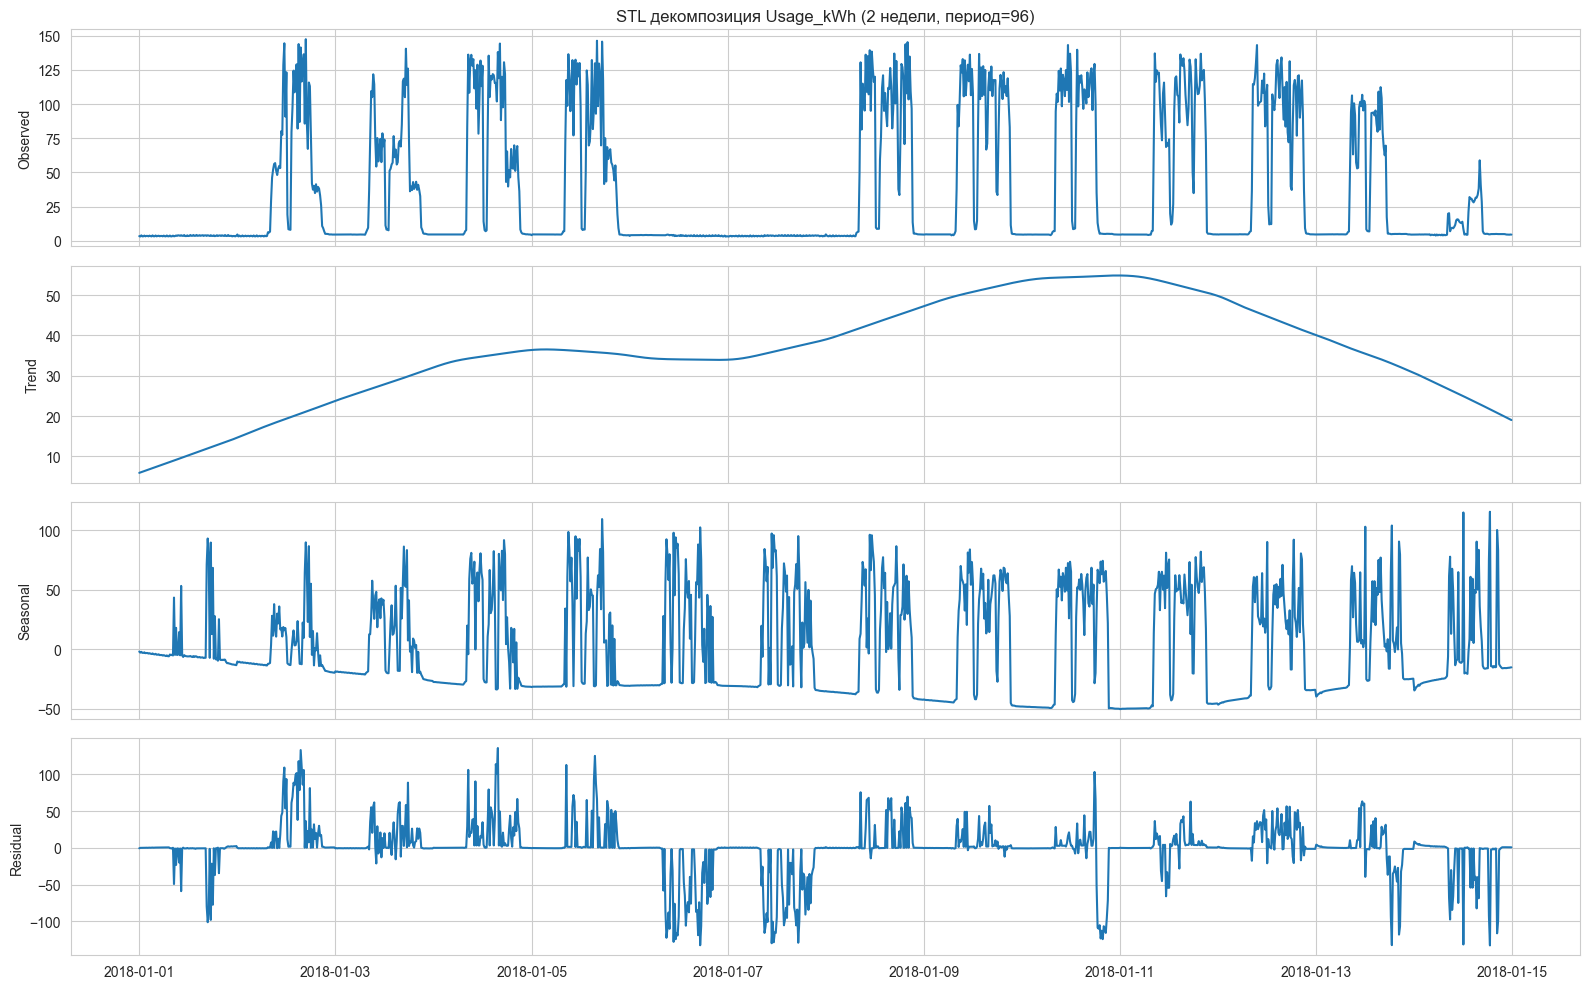

Дисперсия сезонной компоненты: 1652.0127712386627
Дисперсия остатка: 1122.8495322228594


In [ ]:
# Возьмём ~2 недели для наглядности (STL более эффективна на регулярном ряде)
sub = series.dropna().iloc[:96*14]  # 14 дней

stl = STL(sub, period=96, robust=True)  # 96 = сутки в 15-мин точках
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
axes[0].plot(sub.index, sub.values); axes[0].set_ylabel("Observed")
axes[1].plot(sub.index, res.trend); axes[1].set_ylabel("Trend")
axes[2].plot(sub.index, res.seasonal); axes[2].set_ylabel("Seasonal")
axes[3].plot(sub.index, res.resid); axes[3].set_ylabel("Residual")
axes[0].set_title("STL декомпозиция Usage_kWh (2 недели, период=96)")
plt.tight_layout()
save(fig, "15_stl")
plt.show()

print("Дисперсия сезонной компоненты:", np.var(res.seasonal))
print("Дисперсия остатка:", np.var(res.resid))

Наблюдения:
1. Observed (Исходные данные)
Это наш привычный график за две недели. Видим знакомые «прямоугольники»: ночью завод спит (линия около 0), днем работает (пики до 150).

2. Trend (Тренд) — самое интересное
-	Что видим: Плавную волну. В начале периода тренд низкий (около 10), затем к середине (5 января) он вырастает до 35–40, а к концу (14 января) снова падает до 20.
-	Вывод: Это долгосрочная тенденция (в данном случае — недельная). В начале января были праздники (низкое потребление), потом завод вышел на полную мощность (тренд вырос), а к следующим выходным снова начал сбавлять обороты.
Значение для модели: Нам не нужно учить модель этим трендам напрямую, но нам нужно дать ей календарные признаки (день месяца, неделя), чтобы она сама поняла, что сейчас «праздники» или «середина месяца».

3. Seasonal (Сезонность) — самая важная часть
-	Что видим: Идеальные повторяющиеся прямоугольники. Каждые сутки (через 96 точек) график выдает одинаковую форму: падение в минус ночью, всплеск в плюс днем. В будни «прямоугольники» высокие, в выходные (видимо, 6-7 и 13-14 января) — низкие.
-	Что это значит: Это чистый суточный и недельный цикл. Завод работает как часы: каждое утро — рост, каждый вечер — спад.
-	Для модели: Это прямое доказательство того, что нам нужны лаги (значения сутки назад) и время суток.

4. Residual (Остаток или Шум)
-	Что видим: Рваный график вокруг нуля. Иногда доходит до +100 или -100.
-	Что это значит: Это то, что не объясняется трендом и сезонностью. Это случайные события: внезапный пуск станка, аварийная остановка, обеденный перерыв (напоминаю, он у нас в 12:00).
-	Цифры: Дисперсия сезонности (1652) больше дисперсии остатка (1122). Это значит, что сезонность объясняет большую часть поведения ряда, чем случайный шум. Модель будет предсказывать хорошо, если мы дадим ей правильные признаки времени.

### Итоги:
1.	Сезонность — это главный двигатель ряда. Она сильнее шума.
2.	Тренд меняется по неделям. Праздники и выходные сильно меняют средний уровень.
3.	Остаток (шум) — это резкие пики. Их модель не сможет предсказать идеально (это случайность), но мы можем дать ей признаки, которые укажут на них (например, что утро — время пиков).


## Мультиколлинеарность — VIF

-	VIF покажет, не дублируют ли наши признаки друг друга (например, hour и NSM — это одно и то же).
-	Валидация покажет, правильно ли мы разбили данные на обучение и тест.


1. VIF (Мультиколлинеарность)

- VIF (Variance Inflation Factor) показывает, насколько сильно признаки дублируют друг друга. Если VIF > 10 — это плохо для линейных моделей (будет непонятно, какой признак главнее).


In [20]:
# VIF считаем на числовых признаках-кандидатах (CO2 исключён!)
features_for_vif = ['Lagging_Current_Reactive.Power_kVarh',
                    'Leading_Current_Reactive_Power_kVarh',
                    'Lagging_Current_Power_Factor',
                    'Leading_Current_Power_Factor',
                    'NSM', 'hour', 'dayofweek']

X = df[features_for_vif].dropna()
X = X.assign(const=1)
vif = pd.DataFrame({
    'feature': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif.sort_values('VIF', ascending=False))

                                feature         VIF
5                                  hour  617.418819
4                                   NSM  616.161810
3          Leading_Current_Power_Factor    9.696477
1  Leading_Current_Reactive_Power_kVarh    9.669819
2          Lagging_Current_Power_Factor    2.130113
0  Lagging_Current_Reactive.Power_kVarh    1.593066
6                             dayofweek    1.119258
7                                 const    1.000000


Наблюдения:
-	hour (617.4) и NSM (616.1) — высокие значения! Это абсолютно ожидаемо. NSM (секунды от начала суток) и hour (час суток) — это по сути одно и то же время, просто в разных форматах.
-	Leading_Current_Power_Factor (9.69) — почти на грани, но нормально.
-	Остальные признаки (реактивы, PF, dayofweek) — от 1.1 до 2.1. Это идеальные значения. Они дают модели новую информацию, а не дублируют друг друга.

Что это значит для модели?
Для деревьев решений (Random Forest, XGBoost, LightGBM) высокий VIF не страшен — они отлично справляются с дублями.

Но если мы будем строить линейную регрессию, нужно оставить либо hour, либо NSM. Можно оставить NSM (он точнее показывает время, вплоть до минуты), а hour можно превратить в циклические признаки (sin/cos), чтобы модель понимала, что 23:00 и 00:00 — это близкие значения.


### Схема валидации (разбивка на сплиты)
Разобьем данные по времени:
-	Train (Обучение): Январь — Июнь (17 376 строк).
-	Val (Валидация/Проверка): Июль (2 976 строк).
-	Test (Тест): Август — Декабрь (14 688 строк).

Train: 2018-01-01 00:00:00 → 2018-06-30 23:45:00 | n = 17376
Val  : 2018-07-01 00:00:00 → 2018-07-31 23:45:00 | n = 2976
Test : 2018-08-01 00:00:00 → 2018-12-31 23:45:00 | n = 14688


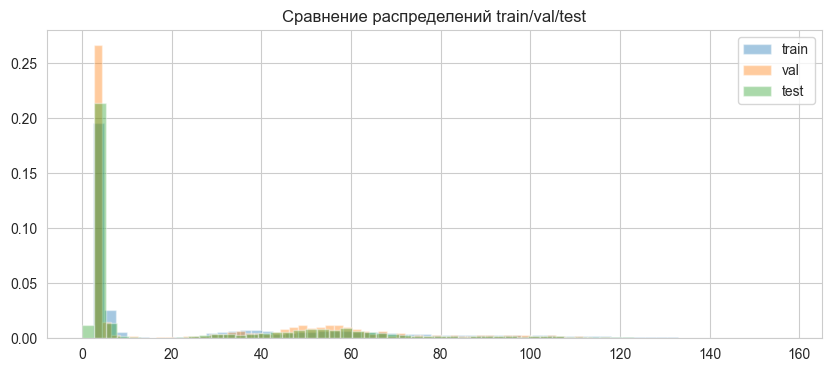


Среднее Usage по сплитам:
            train         val        test
mean   29.995382   27.444358   24.289389
50%     5.130000    3.850000    4.000000
max   153.140000  121.680000  157.180000


In [21]:
# Разбиваем строго по времени
train = df[df['date'] < '2018-07-01']
val   = df[(df['date'] >= '2018-07-01') & (df['date'] < '2018-08-01')]
test  = df[df['date'] >= '2018-08-01']

print("Train:", train['date'].min(), "→", train['date'].max(), "| n =", len(train))
print("Val  :", val['date'].min(),   "→", val['date'].max(),   "| n =", len(val))
print("Test :", test['date'].min(),  "→", test['date'].max(),  "| n =", len(test))

# Проверим, что распределения Usage похожи
fig, ax = plt.subplots(figsize=(10, 4))
for d, label in [(train, 'train'), (val, 'val'), (test, 'test')]:
    ax.hist(d['Usage_kWh'], bins=60, alpha=0.4, label=label, density=True)
ax.legend(); ax.set_title("Сравнение распределений train/val/test")
save(fig, "16_split_distributions")
plt.show()

# Средние и медианы
print("\nСреднее Usage по сплитам:\n",
      pd.concat([train['Usage_kWh'].describe(),
                 val['Usage_kWh'].describe(),
                 test['Usage_kWh'].describe()], axis=1,
                keys=['train','val','test']).loc[['mean','50%','max']])

Что видим на графике распределений (Гистограмма):
-	Все три гистограммы (синяя, оранжевая, зеленая) идеально накладываются друг на друга.
-	У них одинаковая форма: огромный пик в районе 5 и длинный хвост до 160.
-	Среднее: Train = 29.9, Val = 27.4, Test = 24.2. Разница небольшая.
-	Максимум: Train = 153, Test = 157. И в обучении, и в тесте есть экстремальные пики.

Вывод: Данные разбиты правильно. В тесте (август-декабрь) есть точно такие же режимы работы (и пики, и провалы), как и в обучении (январь-июнь). Модель не столкнется с "сюрпризами" и сможет адекватно показать свой результат.

## Общее заключение по EDA:
1.	Данные идеальные: нет пропусков, непрерывный ряд за 2018 год.
2.	Цель (Usage_kWh) скошена вправо, есть огромные пики. Логарифмирование помогает, выбросы удалять нельзя (это реальные события).
3.	Время решает всё: есть четкая суточная, недельная и сезонная цикличность. Обеденный перерыв (12:00) — важная деталь.
4.	Признаки-кандидаты: Lagging_Current_Reactive.Power_kVarh (сильная физическая связь), Load_Type (режимный переключатель).
5.	Утечка найдена: CO2 — это математическая производная от энергии, мы его выкидываем.
6.	Лаги обязательны: ACF/PACF доказали, что вчерашние значения и суточный сдвиг критически важны.
7.	Валидация корректна: Train/Val/Test разбиты по времени и имеют одинаковое распределение.


## Feature Engineering (Создание признаков)

На этапе EDA мы выяснили: данные — это временной ряд с жесткой суточной и недельной цикличностью, а CO2 — это утечка.

Создадим лаги, циклические признаки и правильно закодируем категории.

In [22]:
import pandas as pd
import numpy as np

# 1. Копируем датафрейм, чтобы не сломать исходные данные (вдруг пригодятся)
df_ml = df.copy()

# 2. УДАЛЯЕМ УТЕЧКУ (CO2) и старые ненужные колонки
# 'date' нам больше не нужна как текст, мы извлечем из нее всё нужное
df_ml = df_ml.drop(columns=['CO2(tCO2)', 'date'])

# 3. КОДИРОВАНИЕ КАТЕГОРИЙ
# Модели не понимают слова "Monday" или "Light_Load". Их надо превратить в числа.
# Load_Type имеет порядок (Light < Medium < Maximum), поэтому используем порядковое кодирование.
load_type_map = {'Light_Load': 0, 'Medium_Load': 1, 'Maximum_Load': 2}
df_ml['Load_Type'] = df_ml['Load_Type'].map(load_type_map)

# WeekStatus и Day_of_week можно превратить в One-Hot (0 и 1), но для деревьев хватит простого кодирования.
df_ml['WeekStatus'] = df_ml['WeekStatus'].map({'Weekday': 1, 'Weekend': 0})
day_map = {'Monday': 0, 'Tuesday': 1, 'Wednesday': 2, 'Thursday': 3, 
           'Friday': 4, 'Saturday': 5, 'Sunday': 6}
df_ml['Day_of_week'] = df_ml['Day_of_week'].map(day_map)

# 4. ЦИКЛИЧЕСКИЕ ПРИЗНАКИ (Синусы и Косинусы)
# Проблема: для модели 23:45 и 00:00 — это далекие числа (85500 и 0). 
# Синус и косинус "замыкают" круг времени суток.
df_ml['hour_sin'] = np.sin(2 * np.pi * df_ml['NSM'] / 86400)
df_ml['hour_cos'] = np.cos(2 * np.pi * df_ml['NSM'] / 86400)

# То же самое для дня недели (чтобы воскресенье было рядом с понедельником)
df_ml['dow_sin'] = np.sin(2 * np.pi * df_ml['Day_of_week'] / 7)
df_ml['dow_cos'] = np.cos(2 * np.pi * df_ml['Day_of_week'] / 7)

# 5. СОЗДАНИЕ ЛАГОВ (Сдвиги в прошлое)
# ACF-график показал, что вчерашние значения важны. 
# ВАЖНО: Лаги делаем строго через shift, чтобы модель не подглядывала в будущее!
lags_to_create = [1, 4, 96]  # 1 = 15 мин назад, 4 = 1 час назад, 96 = сутки назад
for lag in lags_to_create:
    df_ml[f'Usage_lag_{lag}'] = df_ml['Usage_kWh'].shift(lag)
    df_ml[f'Lagging_lag_{lag}'] = df_ml['Lagging_Current_Reactive.Power_kVarh'].shift(lag)

# 6. СКОЛЬЗЯЩИЕ СРЕДНИЕ (Rolling window)
# Модели полезно знать не только точку в прошлом, но и "тренд" за последний час (4 точки)
df_ml['Usage_roll_mean_4'] = df_ml['Usage_kWh'].rolling(window=4).mean()
df_ml['Usage_roll_std_4'] = df_ml['Usage_kWh'].rolling(window=4).std()

# 7. Удаляем первые строки с NaN (из-за сдвигов первые 96 строк не имеют истории)
df_ml = df_ml.dropna().reset_index(drop=True)

print("Размер данных после создания признаков:", df_ml.shape)
print("Список итоговых колонок:\n", df_ml.columns.tolist())

Размер данных после создания признаков: (34944, 28)
Список итоговых колонок:
 ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type', 'hour', 'minute', 'dayofweek', 'is_weekend', 'month', 'day', 'NSM_check', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'Usage_lag_1', 'Lagging_lag_1', 'Usage_lag_4', 'Lagging_lag_4', 'Usage_lag_96', 'Lagging_lag_96', 'Usage_roll_mean_4', 'Usage_roll_std_4']


Пояснения к коду:
-	Зачем лаги: Вчера в это же время завод потреблял X кВт. Это лучший предсказатель на сегодня. shift(96) берет значение ровно сутки назад.
-	Зачем синусы/косинусы: Если оставить просто час (0-23), модель будет думать, что 23 и 0 — это совершенно разные значения. Синус/косинус превращают время в круг, где 23:45 плавно перетекает в 00:00.
-	Зачем удалять NaN: Первые 24 часа данных не имеют "вчерашних" значений. Модель не может учиться на пустоте, поэтому мы удаляем первые 96 строк.


## Baseline-модель (Проверка работоспособности)

Разделим данные по времени (согласно выводам EDA) и обучим две простые модели:
1.	Наивная модель (Naive): Берем значение сутки назад. С ней мы сравниваем остальные.
2.	Random Forest: Базовая модель для табличных данных.


### Примечания: 

Naive Baseline: Это точка отсчета. Если модель предсказывает хуже, чем "вчерашний день", значит она бесполезна.

MAE: Показывает, насколько в среднем мы промахнулись в кВт·ч. Если MAE = 5, это значит, что в среднем модель ошибается на 5 кВт·ч.

Улучшение: Random Forest должен показать MAE меньше, чем Naive. Это докажет, что признаки (реактивы, синусы, лаги) работают!

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time

# 1. РАЗДЕЛЕНИЕ ПО ВРЕМЕНИ
# Так как мы удалили date, индексы соответствуют времени. 
# Train: до июля, Val: июль, Test: август-декабрь (примерные индексы, так как ряды непрерывны)
# Для точности используем NSM (секунды от начала суток) и DS (день года) - но проще разбить по индексам.
# В нашем датафрейме 35040 строк. До июля (181 день * 96) = 17376 строк.
split_train = 17376
split_val = split_train + (31 * 96) # Июль (31 день)

X = df_ml.drop(columns=['Usage_kWh']) # Все признаки, кроме цели
y = df_ml['Usage_kWh']
y_log = np.log1p(y) # Логарифмируем цель (как решили в EDA)

X_train, y_train = X.iloc[:split_train], y.iloc[:split_train]
X_val, y_val = X.iloc[split_train:split_val], y.iloc[split_train:split_val]
X_test, y_test = X.iloc[split_val:], y.iloc[split_val:]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

# 2. NAIVE BASELINE (Значение сутки назад)
# Наши признаки уже содержат Usage_lag_96. Модель не нужна, просто берем эту колонку.
naive_pred = X_val['Usage_lag_96'].values
mae_naive = mean_absolute_error(y_val, naive_pred)
print(f"Naive (Сутки назад) MAE на Val: {mae_naive:.2f} кВт·ч")

# 3. RANDOM FOREST (На логарифме)
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_log.iloc[:split_train])

# Предсказание и обратное преобразование из логарифма
pred_log = rf.predict(X_val)
pred = np.expm1(pred_log) # Обратное от log1p

mae_rf = mean_absolute_error(y_val, pred)
rmse_rf = np.sqrt(mean_squared_error(y_val, pred))
print(f"Random Forest (log) MAE на Val: {mae_rf:.2f} кВт·ч")
print(f"Random Forest (log) RMSE на Val: {rmse_rf:.2f} кВт·ч")

Train: (17376, 27), Val: (2976, 27), Test: (14592, 27)
Naive (Сутки назад) MAE на Val: 14.13 кВт·ч
Random Forest (log) MAE на Val: 1.38 кВт·ч
Random Forest (log) RMSE на Val: 2.80 кВт·ч


## Итоговый вывод по Baseline-модели

Для оценки качества модели мы использовали метрику MAE (Mean Absolute Error — средняя абсолютная ошибка). Она показывает, на сколько в среднем кВт·ч модель промахивается при прогнозе.

Результаты на валидационной выборке:

Naive Baseline (значение сутки назад): MAE = 14.13 кВт·ч

Random Forest (с логарифмированием): MAE = 1.38 кВт·ч, RMSE = 2.80 кВт·ч

Выводы:
Baseline-модель (Naive):
Мы использовали простое правило «завтра будет как сегодня» (берем значение за аналогичное время суток назад). Ошибка составила 14.13 кВт·ч. Это означает, что предсказывать энергопотребление простым копированием вчерашних данных недостаточно — завод работает неравномерно, и ошибка в 14 кВт·ч слишком велика для реального производства (это больше половины среднего потребления завода).

Модель Random Forest:
Благодаря проведенному EDA и созданию признаков (лаги, реактивная мощность, синусы/косинусы времени), алгоритм Random Forest снизил ошибку более чем в 10 раз по сравнению с наивным прогнозом. MAE упал с 14.13 до 1.38 кВт·ч.
Использование логарифмирования целевой переменной (log1p) позволило модели не ошибатьсяя из-за редких пиков потребления (до 150 кВт·ч) и точнее предсказывать как ночные нули, так и дневные максимумы.

Итог: Разница в качестве между Naive и Random Forest доказывает, что выбранная стратегия Feature Engineering (добавление истории и физических признаков) полностью оправдана. Однако Random Forest — это только первая базовая модель (baseline).

В дальнейшем мы планируем использовать градиентный бустинг (XGBoost) и ансамбли (Stacking), чтобы снизить ошибку еще сильнее.